In [1]:
import math
import numpy as np

In [13]:
def format_string(var_type_and_name, str_values, vals_per_column=8):
    # try to get a result not too ugly...
    concatenated_strings = []
    for k in range(0, len(str_values), vals_per_column):
        concatenated_strings.append( ',\t'.join(str_values[k:k+vals_per_column]) )
    
    concatenated = ',\n'.join(concatenated_strings)
    total_str = f"const {var_type_and_name}[{len(str_values)}] PROGMEM = {{\n{concatenated}}};"

    return total_str

# potentiometer to hertz conversion

In [21]:
# following the equations provided here:
# https://electronics.stackexchange.com/questions/304692/formula-for-logarithmic-audio-taper-pot

bits_depth = 10

num_values = 2 ** bits_depth

# min and max values included in the current coven lfo version
min_val = 0.0001
mid_val = 1.722775
max_val = 104.02084

# the taper will be considered as a function y=f(x) where x€[0,1] and y€[0,1]
# resulting value res(x) = min_val * (1-f(x)) + max_val * f(x)
# or more simply: res(x) = min_val + f(x) * (max_val - min_val)
# so following the stackexchange link, ym = (mid_val - min_val) / (max_val - min_val)
# let's implement it now

y_m = (mid_val - min_val) / (max_val - min_val)
b = ((1. / y_m) - 1.) ** 2
a = 1. / (b - 1.)

x_values = np.linspace(0., 1., num=num_values)
y_values = a * (b ** x_values) - a

res_values = min_val + (max_val - min_val) * y_values

# how we will represent the values
str_values = [f"{val:.8}" for val in res_values.tolist()]

print(format_string("float hzcurve", str_values))


const float hzcurve[1024] PROGMEM = {
0.0001,	0.00033653278,	0.00057496169,	0.00081530192,	0.0010575688,	0.0013017778,	0.0015479444,	0.0017960844,
0.0020462136,	0.0022983479,	0.0025525034,	0.0028086963,	0.0030669429,	0.0033272597,	0.0035896633,	0.0038541705,
0.004120798,	0.0043895628,	0.0046604822,	0.0049335734,	0.0052088538,	0.0054863409,	0.0057660524,	0.0060480062,
0.0063322203,	0.0066187127,	0.0069075017,	0.0071986058,	0.0074920434,	0.0077878334,	0.0080859945,	0.0083865457,
0.0086895063,	0.0089948955,	0.0093027329,	0.0096130379,	0.0099258305,	0.01024113,	0.010558958,	0.010879333,
0.011202277,	0.01152781,	0.011855952,	0.012186724,	0.012520148,	0.012856245,	0.013195036,	0.013536544,
0.013880788,	0.014227793,	0.014577579,	0.014930169,	0.015285585,	0.015643851,	0.016004988,	0.016369021,
0.016735972,	0.017105864,	0.017478722,	0.017854569,	0.018233428,	0.018615325,	0.019000283,	0.019388327,
0.019779481,	0.020173772,	0.020571223,	0.02097186,	0.021375709,	0.021782795,	0.022193144,	0.0226067

# LUT for 2^x float values, for the CV control
This operator allows us to get V/Oct results

In [31]:
bitsdepth = 9

num_values = 2 ** bitsdepth

# the linspace is one value bigger because it will correspond in the table to 2^N - 1
np_values = 2. ** np.linspace(0, 1, num=num_values, endpoint=False)

str_values = [f"{val:.8}" for val in np_values.tolist()]

print(format_string("float pow2curve", str_values))


const float pow2curve[512] PROGMEM = {
1.0,	1.0013547,	1.0027113,	1.0040697,	1.0054299,	1.006792,	1.0081559,	1.0095217,
1.0108893,	1.0122588,	1.0136301,	1.0150033,	1.0163783,	1.0177552,	1.019134,	1.0205146,
1.0218971,	1.0232815,	1.0246678,	1.0260559,	1.0274459,	1.0288379,	1.0302316,	1.0316273,
1.0330249,	1.0344243,	1.0358257,	1.0372289,	1.0386341,	1.0400412,	1.0414501,	1.042861,
1.0442738,	1.0456885,	1.0471051,	1.0485236,	1.0499441,	1.0513665,	1.0527908,	1.054217,
1.0556452,	1.0570753,	1.0585073,	1.0599413,	1.0613772,	1.0628151,	1.0642549,	1.0656967,
1.0671404,	1.0685861,	1.0700337,	1.0714833,	1.0729349,	1.0743884,	1.0758439,	1.0773014,
1.0787608,	1.0802222,	1.0816856,	1.083151,	1.0846184,	1.0860877,	1.0875591,	1.0890324,
1.0905077,	1.0919851,	1.0934644,	1.0949457,	1.0964291,	1.0979144,	1.0994018,	1.1008912,
1.1023826,	1.103876,	1.1053714,	1.1068689,	1.1083684,	1.1098699,	1.1113735,	1.1128791,
1.1143867,	1.1158964,	1.1174082,	1.1189219,	1.1204378,	1.1219556,	1.1234756,	1.1249976,
1.126

# SINE curve of range N at depth M
for an oscillator, sine curve where the output depth is N bits and the input variable depth is M bits

In [24]:
n_bits_input = 10 # M
n_bits_output = 9 # N

num_values = 2 ** n_bits_input
max_val = (2 ** n_bits_output) - 1

# we normalize to 0-2 then multiply by the max_val to get the full range
np_values = (np.cos( np.linspace(-np.pi, np.pi, num=num_values, endpoint=False)) + 1 ) * float(max_val / 2)

str_values = [f"{val}" for val in np.round(np_values).astype(np.uint16).tolist()]

print(format_string("uint16_t sin_curve", str_values, 16))


const uint16_t sin_curve[1024] PROGMEM = {
0,	0,	0,	0,	0,	0,	0,	0,	0,	0,	0,	1,	1,	1,	1,	1,
1,	1,	2,	2,	2,	2,	2,	3,	3,	3,	3,	3,	4,	4,	4,	5,
5,	5,	6,	6,	6,	7,	7,	7,	8,	8,	8,	9,	9,	10,	10,	11,
11,	11,	12,	12,	13,	13,	14,	14,	15,	15,	16,	17,	17,	18,	18,	19,
19,	20,	21,	21,	22,	23,	23,	24,	25,	25,	26,	27,	27,	28,	29,	29,
30,	31,	32,	32,	33,	34,	35,	36,	36,	37,	38,	39,	40,	40,	41,	42,
43,	44,	45,	46,	47,	48,	48,	49,	50,	51,	52,	53,	54,	55,	56,	57,
58,	59,	60,	61,	62,	63,	64,	65,	66,	67,	68,	69,	70,	72,	73,	74,
75,	76,	77,	78,	79,	80,	82,	83,	84,	85,	86,	87,	89,	90,	91,	92,
93,	95,	96,	97,	98,	100,	101,	102,	103,	105,	106,	107,	108,	110,	111,	112,
114,	115,	116,	117,	119,	120,	121,	123,	124,	125,	127,	128,	130,	131,	132,	134,
135,	136,	138,	139,	141,	142,	143,	145,	146,	148,	149,	151,	152,	153,	155,	156,
158,	159,	161,	162,	164,	165,	166,	168,	169,	171,	172,	174,	175,	177,	178,	180,
181,	183,	184,	186,	187,	189,	190,	192,	193,	195,	196,	198,	200,	201,	203,	204,
206,	207,	209,	210,	212,	213,	2

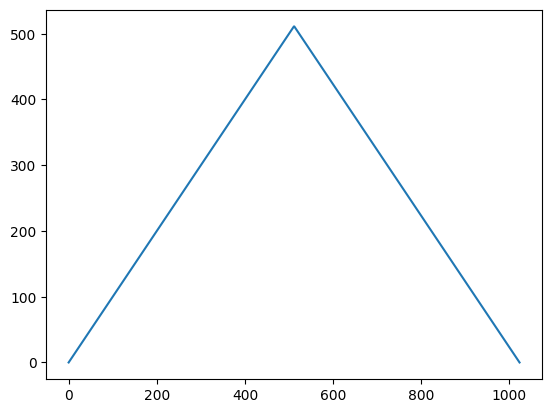

In [30]:
import matplotlib.pyplot as plt

test_vals = np.arange(2 ** 10)

test_wave = test_vals.copy()
test_wave[test_wave>=(2 ** 9)] ^= (2**10)-1

plt.plot(test_vals, test_wave)
